# Emotion Classification: Lightweight MLP vs. Pretrained Transformer

**Author:** Apurva Palaniappan  
**Dataset:** DAIR-AI Emotion (`dair-ai/emotion`, split configuration)

This project compares a lightweight PyTorch classifier trained from scratch with a
pretrained DistilBERT transformer. Both models use the same official train,
validation and test splits and are evaluated with accuracy and macro-F1. The
analysis also tests robustness on a manually annotated literary out-of-domain set.

The first part develops and tunes the custom MLP. The final section fine-tunes
DistilBERT and performs the controlled model comparison.

### Dataset

The corpus contains 20,000 English social-media texts: 16,000 training examples,
2,000 validation examples and 2,000 test examples. Each text is labelled as one
of six emotions: sadness, joy, love, anger, fear or surprise.

The dataset is connected to the CARER work by Saravia et al. (2018). See the
[paper](https://aclanthology.org/D18-1404/), the
[Hugging Face dataset card](https://huggingface.co/datasets/dair-ai/emotion), and
the [dataset repository](https://github.com/dair-ai/emotion_dataset).


---

## 1. Setup

In [1]:
# Installing the libraries required for this project
!pip install -q datasets==5.0.1 transformers==5.16.1 accelerate

import os
import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import datasets
import transformers

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from transformers import (
    AutoTokenizer,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    Trainer,
    TrainingArguments
)

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

warnings.filterwarnings("ignore")

# Display environment information
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)
print("PyTorch version:", torch.__version__)
print("Transformers version:", transformers.__version__)
print("Datasets version:", datasets.__version__)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 59.6 MB/s eta 0:00:00
Device: cuda
PyTorch version: 2.11.0+cu130
Transformers version: 5.16.1
Datasets version: 5.0.1
GPU: Tesla T4


---

## 2. Data download and preprocessing

### 2.1. Download the corpus

In [2]:
# Load the official pre-split version of the Emotion corpus
dataset = datasets.load_dataset("dair-ai/emotion", "split")

print(dataset)
print("\nDataset features:")
print(dataset["train"].features)

label_names = dataset["train"].features["label"].names
id2label = {i: label for i, label in enumerate(label_names)}
label2id = {label: i for i, label in id2label.items()}

print("\nLabel mapping:")
for label_id, label_name in id2label.items():
    print(f"{label_id}: {label_name}")

print("\nExample training item:")
print(dataset["train"][0])

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})

Dataset features:
{'text': Value('string'), 'label': ClassLabel(names=['sadness', 'joy', 'love', 'anger', 'fear', 'surprise'])}

Label mapping:
0: sadness
1: joy
2: love
3: anger
4: fear
5: surprise

Example training item:
{'text': 'i didnt feel humiliated', 'label': 0}


### 2.2. Preprocessing

The Emotion dataset already has separate training, validation, and test sets, so I kept these original splits instead of creating new ones. Before preprocessing the text, I checked the number of examples in each split, whether there were any empty or duplicate texts, whether the same texts appeared across different splits, and how the six emotion labels were distributed.

,split,examples,empty_texts,unique_texts,duplicate_occurrences
0,train,16000,0,15969,31
1,validation,2000,0,1998,2
2,test,2000,0,2000,0


,split_pair,overlapping_texts
0,train–validation,5
1,train–test,11
2,validation–test,3


split,test,train,validation
label,,,
sadness,581,4666,550
joy,695,5362,704
love,159,1304,178
anger,275,2159,275
fear,224,1937,212
surprise,66,572,81


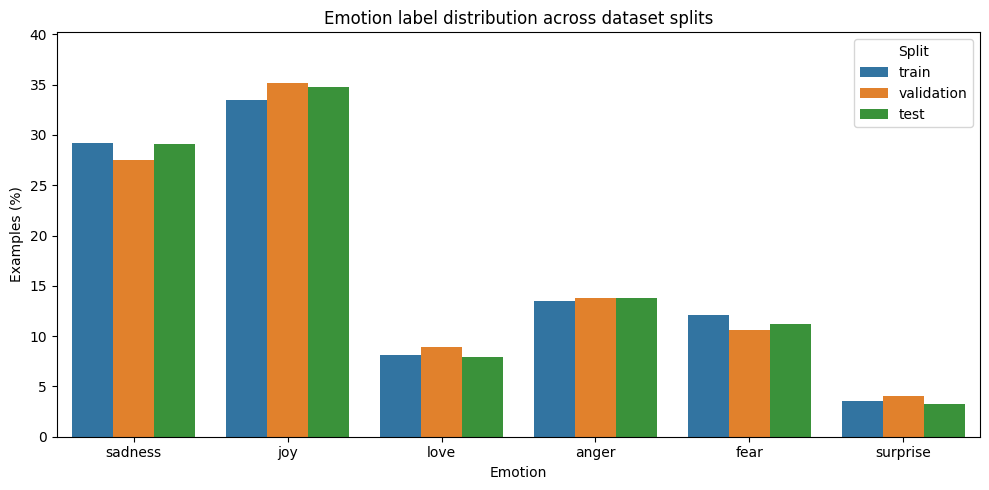

In [3]:
# Inspect dataset integrity
split_statistics = []

for split_name, split_data in dataset.items():
    texts = split_data["text"]

    split_statistics.append({
        "split": split_name,
        "examples": len(split_data),
        "empty_texts": sum(not text.strip() for text in texts),
        "unique_texts": len(set(texts)),
        "duplicate_occurrences": len(texts) - len(set(texts))
    })

split_statistics_df = pd.DataFrame(split_statistics)
display(split_statistics_df)

# Check exact text overlap between different splits
text_sets = {
    split_name: set(split_data["text"])
    for split_name, split_data in dataset.items()
}

overlap_statistics = pd.DataFrame([
    {
        "split_pair": "train–validation",
        "overlapping_texts": len(
            text_sets["train"] & text_sets["validation"]
        )
    },
    {
        "split_pair": "train–test",
        "overlapping_texts": len(
            text_sets["train"] & text_sets["test"]
        )
    },
    {
        "split_pair": "validation–test",
        "overlapping_texts": len(
            text_sets["validation"] & text_sets["test"]
        )
    }
])

display(overlap_statistics)

# Calculate label counts and proportions for every split
distribution_rows = []

for split_name, split_data in dataset.items():
    labels = np.array(split_data["label"])

    for label_id, label_name in id2label.items():
        count = int(np.sum(labels == label_id))

        distribution_rows.append({
            "split": split_name,
            "label": label_name,
            "count": count,
            "percentage": 100 * count / len(labels)
        })

distribution_df = pd.DataFrame(distribution_rows)

display(
    distribution_df.pivot(
        index="label",
        columns="split",
        values="count"
    ).loc[label_names]
)

# Plot the class distribution
plt.figure(figsize=(10, 5))

sns.barplot(
    data=distribution_df,
    x="label",
    y="percentage",
    hue="split"
)

plt.title("Emotion label distribution across dataset splits")
plt.xlabel("Emotion")
plt.ylabel("Examples (%)")
plt.ylim(0, distribution_df["percentage"].max() + 5)
plt.legend(title="Split")
plt.tight_layout()
plt.show()

,split,mean_words,median_words,maximum_words,95th_percentile
0,train,19.17,17.0,66,41.0
1,validation,18.87,17.0,61,40.0
2,test,19.15,17.0,61,41.0


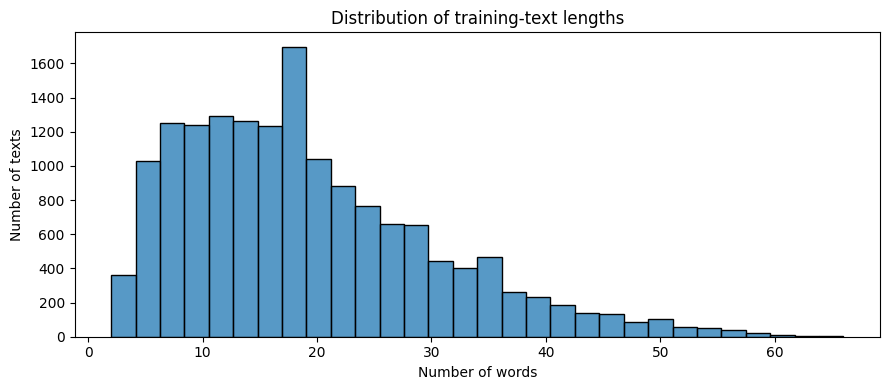

Filter:   0%|          | 0/16000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/16000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/16000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/16000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/16000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/16000 [00:00<?, ? examples/s]

,emotion,text
0,sadness,i didnt feel humiliated
1,sadness,i can go from feeling so hopeless to so damned...
2,joy,i have been with petronas for years i feel tha...
3,joy,i do feel that running is a divine experience ...
4,love,i am ever feeling nostalgic about the fireplac...
5,love,i feel romantic too
6,anger,im grabbing a minute to post i feel greedy wrong
7,anger,i am feeling grouchy
8,fear,i feel as confused about life as a teenager or...
9,fear,i now feel compromised and skeptical of the va...


In [4]:
# Inspect text lengths and examples from each emotion class
length_rows = []

for split_name, split_data in dataset.items():
    word_counts = [len(text.split()) for text in split_data["text"]]

    length_rows.append({
        "split": split_name,
        "mean_words": np.mean(word_counts),
        "median_words": np.median(word_counts),
        "maximum_words": np.max(word_counts),
        "95th_percentile": np.percentile(word_counts, 95)
    })

length_statistics_df = pd.DataFrame(length_rows)
display(length_statistics_df.round(2))

# Plot the training-text length distribution
train_word_counts = [
    len(text.split())
    for text in dataset["train"]["text"]
]

plt.figure(figsize=(9, 4))

sns.histplot(
    train_word_counts,
    bins=30
)

plt.title("Distribution of training-text lengths")
plt.xlabel("Number of words")
plt.ylabel("Number of texts")
plt.tight_layout()
plt.show()

# Display two training examples from every emotion class
example_rows = []

for label_id, label_name in id2label.items():
    label_examples = dataset["train"].filter(
        lambda example: example["label"] == label_id
    ).select(range(2))

    for example in label_examples:
        example_rows.append({
            "emotion": label_name,
            "text": example["text"]
        })

examples_df = pd.DataFrame(example_rows)
display(examples_df)

The texts are quite short. The average length is around 19 words, and 95% of the texts contain 41 words or fewer. The length distributions are also very similar across the three splits. Since even the longest text contains only 66 words, I decided to keep the complete texts without truncating them.

The MLP cannot directly process text, so the texts first need to be converted into token IDs. Following the approach used in the course exercises, I trained a new tokenizer vocabulary using only the training texts. The validation and test texts were not used when creating the vocabulary.

In [5]:
# Train a tokenizer using only the training texts
BASE_TOKENIZER = "google-bert/bert-base-uncased"
VOCAB_SIZE = 15000

base_tokenizer = AutoTokenizer.from_pretrained(BASE_TOKENIZER)

tokenizer = base_tokenizer.train_new_from_iterator(
    dataset["train"]["text"],
    vocab_size=VOCAB_SIZE
)

print("Requested vocabulary size:", VOCAB_SIZE)
print("Actual vocabulary size:", len(tokenizer))
print("Padding token:", tokenizer.pad_token)
print("Padding token ID:", tokenizer.pad_token_id)
print("Unknown token:", tokenizer.unk_token)
print("Unknown token ID:", tokenizer.unk_token_id)

# Show how one example is tokenized
sample_text = dataset["train"][0]["text"]
sample_encoding = tokenizer(
    sample_text,
    add_special_tokens=False
)

print("\nOriginal text:")
print(sample_text)

print("\nTokens:")
print(tokenizer.convert_ids_to_tokens(sample_encoding["input_ids"]))

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Requested vocabulary size: 15000
Actual vocabulary size: 15000
Padding token: [PAD]
Padding token ID: 0
Unknown token: [UNK]
Unknown token ID: 1

Original text:
i didnt feel humiliated

Tokens:
['i', 'didnt', 'feel', 'humiliated']


In [6]:
# Apply the tokenizer to all three dataset splits
def tokenize_batch(examples):
    return tokenizer(
        examples["text"],
        truncation=False
    )

tokenized_dataset = dataset.map(
    tokenize_batch,
    batched=True,
    remove_columns=["text"]
)

print(tokenized_dataset)

# Inspect tokenization statistics
tokenization_rows = []

for split_name, split_data in tokenized_dataset.items():
    sequence_lengths = [
        len(input_ids)
        for input_ids in split_data["input_ids"]
    ]

    total_tokens = sum(sequence_lengths)
    unknown_tokens = sum(
        input_ids.count(tokenizer.unk_token_id)
        for input_ids in split_data["input_ids"]
    )

    tokenization_rows.append({
        "split": split_name,
        "mean_tokens": np.mean(sequence_lengths),
        "maximum_tokens": np.max(sequence_lengths),
        "unknown_tokens": unknown_tokens,
        "unknown_percentage": (
            100 * unknown_tokens / total_tokens
            if total_tokens > 0 else 0
        )
    })

tokenization_statistics_df = pd.DataFrame(tokenization_rows)
display(tokenization_statistics_df.round(4))

# Create the function that dynamically pads texts within each batch
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Check one small batch
sample_batch = data_collator([
    tokenized_dataset["train"][0],
    tokenized_dataset["train"][1]
])

print("\nBatch contents and shapes:")
for key, value in sample_batch.items():
    print(f"{key}: {tuple(value.shape)}")

Map:   0%|          | 0/16000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 2000
    })
})


,split,mean_tokens,maximum_tokens,unknown_tokens,unknown_percentage
0,train,21.6326,71,0,0.0
1,validation,21.7805,69,0,0.0
2,test,22.0850,65,0,0.0



Batch contents and shapes:
input_ids: (2, 23)
token_type_ids: (2, 23)
attention_mask: (2, 23)
labels: (2,)


The tokenizer produced no unknown tokens in any split. This means that its subword vocabulary could represent all the words in the validation and test sets, even though the vocabulary was created using only the training texts. The sequences also remained short after tokenization, so no truncation was needed. Padding will be added dynamically within each training batch.

---

## 3. Machine learning model

### 3.1. Model training

I used the MLP structure introduced in the course exercises. Each token is mapped to a learned embedding, and the embeddings in each text are added together. A tanh activation is then applied before the output layer predicts one of the six emotion classes. Padding tokens have zero-valued embeddings, so they do not affect the summed representation.

Since the corpus is imbalanced, I used both accuracy and macro-F1. Accuracy measures the overall proportion of correct predictions, while macro-F1 gives equal importance to every emotion class, including the smaller love and surprise classes.

In [7]:
class EmotionMLP(torch.nn.Module):
    def __init__(
        self,
        vocab_size,
        hidden_size,
        num_labels,
        padding_idx=0
    ):
        super().__init__()

        self.embedding = torch.nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=hidden_size,
            padding_idx=padding_idx
        )

        # Use the same small random initialization as the course exercises
        torch.nn.init.uniform_(
            self.embedding.weight.data,
            -0.001,
            0.001
        )

        # Keep the padding embedding fixed at zero
        with torch.no_grad():
            self.embedding.weight[padding_idx].zero_()

        self.output = torch.nn.Linear(
            in_features=hidden_size,
            out_features=num_labels
        )

        self.loss_function = torch.nn.CrossEntropyLoss()

    def forward(
        self,
        input_ids,
        attention_mask=None,
        labels=None,
        **kwargs
    ):
        # Shape: (batch, sequence) -> (batch, sequence, hidden)
        embedded = self.embedding(input_ids)

        # Padding embeddings are zero, so summing ignores padded positions
        embedded_summed = torch.sum(embedded, dim=1)

        # Nonlinear hidden representation
        projected = torch.tanh(embedded_summed)

        # Predict one score for each emotion
        logits = self.output(projected)

        loss = None

        if labels is not None:
            loss = self.loss_function(logits, labels)

        return {
            "loss": loss,
            "logits": logits
        }


def compute_metrics(evaluation_output):
    logits, labels = evaluation_output

    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(
            labels,
            predictions,
            average="macro"
        )
    }


# Create and test the baseline model
BASELINE_HIDDEN_SIZE = 32

baseline_model = EmotionMLP(
    vocab_size=len(tokenizer),
    hidden_size=BASELINE_HIDDEN_SIZE,
    num_labels=len(label_names),
    padding_idx=tokenizer.pad_token_id
)

number_of_parameters = sum(
    parameter.numel()
    for parameter in baseline_model.parameters()
)

print(baseline_model)
print(f"\nNumber of trainable parameters: {number_of_parameters:,}")

# Test a forward pass using the small batch created earlier
baseline_model.eval()

with torch.no_grad():
    test_output = baseline_model(
        input_ids=sample_batch["input_ids"],
        attention_mask=sample_batch["attention_mask"],
        labels=sample_batch["labels"]
    )

print("Test loss:", test_output["loss"].item())
print("Logits shape:", tuple(test_output["logits"].shape))

EmotionMLP(
  (embedding): Embedding(15000, 32, padding_idx=0)
  (output): Linear(in_features=32, out_features=6, bias=True)
  (loss_function): CrossEntropyLoss()
)

Number of trainable parameters: 480,198
Test loss: 1.8073277473449707
Logits shape: (2, 6)


I first trained a baseline model before changing any hyperparameters. The baseline used a hidden size of 32, a learning rate of 0.001, and a batch size of 64. The model was evaluated on the full validation set after every epoch. Early stopping was used to stop training if macro-F1 did not improve for three consecutive evaluations.

In [8]:
# Baseline hyperparameters
BASELINE_LEARNING_RATE = 1e-3
BASELINE_BATCH_SIZE = 64
BASELINE_MAX_EPOCHS = 20

baseline_training_args = TrainingArguments(
    output_dir="baseline_checkpoints",
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    learning_rate=BASELINE_LEARNING_RATE,
    num_train_epochs=BASELINE_MAX_EPOCHS,
    per_device_train_batch_size=BASELINE_BATCH_SIZE,
    per_device_eval_batch_size=128,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=1,
    seed=SEED,
    data_seed=SEED,
    report_to="none"
)

baseline_trainer = Trainer(
    model=baseline_model,
    args=baseline_training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=3
        )
    ]
)

baseline_start_time = time.time()

baseline_train_output = baseline_trainer.train()

baseline_training_time = time.time() - baseline_start_time

baseline_validation_results = baseline_trainer.evaluate()

print("\nBaseline validation results:")
print(
    f"Accuracy: "
    f"{baseline_validation_results['eval_accuracy']:.4f}"
)
print(
    f"Macro-F1: "
    f"{baseline_validation_results['eval_macro_f1']:.4f}"
)
print(
    f"Validation loss: "
    f"{baseline_validation_results['eval_loss']:.4f}"
)
print(
    f"Training time: "
    f"{baseline_training_time / 60:.2f} minutes"
)
print(
    f"Completed training steps: "
    f"{baseline_train_output.global_step}"
)

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.374422,1.026295,0.682000,0.456784
2,0.598561,0.522154,0.867000,0.817592
3,0.245617,0.395161,0.883000,0.844463
4,0.142724,0.365113,0.884500,0.843490
5,0.099201,0.351011,0.884500,0.847922
6,0.075294,0.357502,0.888000,0.849765
7,0.060384,0.360106,0.885000,0.846424
8,0.049986,0.365278,0.885500,0.850230
9,0.042738,0.371870,0.886000,0.849196
10,0.037319,0.386491,0.886500,0.849823


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
0.033128,0.365278,11,0.885500,0.850230



Baseline validation results:
Accuracy: 0.8855
Macro-F1: 0.8502
Validation loss: 0.3653
Training time: 1.01 minutes
Completed training steps: 2750


The baseline reached a validation accuracy of 0.8855 and a macro-F1 of 0.8502. The best macro-F1 was obtained at epoch 8. After that, the training loss continued to decrease, but the validation score did not improve. This suggests that the model had started to overfit the training data. Early stopping ended the training after epoch 11 and restored the model from the best epoch.


### 3.2 Hyperparameter optimization

I tested the hyperparameters in stages instead of trying every possible combination. This made it easier to understand the effect of each parameter. I first compared learning rates while keeping the hidden size and batch size fixed. I then used the selected learning rate to compare hidden sizes, followed by batch sizes. All decisions were made using the validation set. The official test set was not used during hyperparameter optimization.

In [9]:
def run_experiment(
    run_name,
    learning_rate,
    hidden_size,
    batch_size,
    max_epochs=20
):
    # Reset seeds so that comparisons are more reproducible
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    # Every experiment must start with a new model
    model = EmotionMLP(
        vocab_size=len(tokenizer),
        hidden_size=hidden_size,
        num_labels=len(label_names),
        padding_idx=tokenizer.pad_token_id
    )

    training_args = TrainingArguments(
        output_dir=f"experiment_checkpoints/{run_name}",
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="no",
        learning_rate=learning_rate,
        num_train_epochs=max_epochs,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=128,
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        greater_is_better=True,
        save_total_limit=1,
        seed=SEED,
        data_seed=SEED,
        report_to="none",
        disable_tqdm=True
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=tokenized_dataset["train"],
        eval_dataset=tokenized_dataset["validation"],
        data_collator=data_collator,
        compute_metrics=compute_metrics,
        callbacks=[
            EarlyStoppingCallback(
                early_stopping_patience=3
            )
        ]
    )

    start_time = time.time()
    train_output = trainer.train()
    training_minutes = (time.time() - start_time) / 60

    validation_results = trainer.evaluate()

    evaluation_logs = [
        log for log in trainer.state.log_history
        if "eval_macro_f1" in log
    ]

    best_log = max(
        evaluation_logs,
        key=lambda log: log["eval_macro_f1"]
    )

    result = {
        "run": run_name,
        "learning_rate": learning_rate,
        "hidden_size": hidden_size,
        "batch_size": batch_size,
        "validation_accuracy":
            validation_results["eval_accuracy"],
        "validation_macro_f1":
            validation_results["eval_macro_f1"],
        "best_epoch": best_log["epoch"],
        "epochs_completed": trainer.state.epoch,
        "training_minutes": training_minutes,
        "training_steps": train_output.global_step
    }

    print(
        f"{run_name}: "
        f"accuracy={result['validation_accuracy']:.4f}, "
        f"macro-F1={result['validation_macro_f1']:.4f}, "
        f"best epoch={result['best_epoch']:.0f}"
    )

    return result

{'eval_loss': '0.4078', 'eval_accuracy': '0.861', 'eval_macro_f1': '0.8276', 'eval_runtime': '0.4656', 'eval_samples_per_second': '4295', 'eval_steps_per_second': '34.36', 'epoch': '1'}
{'eval_loss': '0.4414', 'eval_accuracy': '0.8575', 'eval_macro_f1': '0.8213', 'eval_runtime': '0.3436', 'eval_samples_per_second': '5820', 'eval_steps_per_second': '46.56', 'epoch': '2'}
{'eval_loss': '0.4794', 'eval_accuracy': '0.8645', 'eval_macro_f1': '0.8296', 'eval_runtime': '0.3078', 'eval_samples_per_second': '6498', 'eval_steps_per_second': '51.99', 'epoch': '3'}
{'eval_loss': '0.5392', 'eval_accuracy': '0.8515', 'eval_macro_f1': '0.8106', 'eval_runtime': '0.3086', 'eval_samples_per_second': '6481', 'eval_steps_per_second': '51.85', 'epoch': '4'}
{'eval_loss': '0.5793', 'eval_accuracy': '0.8585', 'eval_macro_f1': '0.8245', 'eval_runtime': '0.3429', 'eval_samples_per_second': '5833', 'eval_steps_per_second': '46.67', 'epoch': '5'}
{'eval_loss': '0.6099', 'eval_accuracy': '0.856', 'eval_macro_f1':

,learning_rate,validation_accuracy,validation_macro_f1,best_epoch,epochs_completed,training_minutes
3,1e-05,0.3520,0.0868,1.0,4.0,0.15
2,1e-04,0.7165,0.5144,19.0,20.0,1.50
0,1e-03,0.8855,0.8502,8.0,11.0,1.01
1,1e-02,0.8645,0.8296,3.0,6.0,0.48


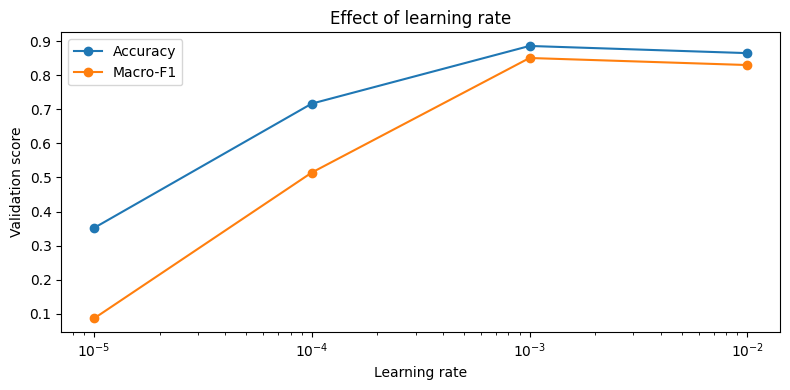

In [10]:
# Store the already completed baseline result
baseline_best_log = max(
    [
        log for log in baseline_trainer.state.log_history
        if "eval_macro_f1" in log
    ],
    key=lambda log: log["eval_macro_f1"]
)

learning_rate_results = [{
    "run": "lr_1e-3_baseline",
    "learning_rate": 1e-3,
    "hidden_size": 32,
    "batch_size": 64,
    "validation_accuracy":
        baseline_validation_results["eval_accuracy"],
    "validation_macro_f1":
        baseline_validation_results["eval_macro_f1"],
    "best_epoch": baseline_best_log["epoch"],
    "epochs_completed": baseline_trainer.state.epoch,
    "training_minutes": baseline_training_time / 60,
    "training_steps": baseline_train_output.global_step
}]

# Test broadly different learning rates
for learning_rate in [1e-2, 1e-4, 1e-5]:
    result = run_experiment(
        run_name=f"lr_{learning_rate:.0e}",
        learning_rate=learning_rate,
        hidden_size=32,
        batch_size=64
    )

    learning_rate_results.append(result)

learning_rate_df = pd.DataFrame(
    learning_rate_results
).sort_values("learning_rate")

# Create a readable version of the results table
learning_rate_display_df = learning_rate_df[
    [
        "learning_rate",
        "validation_accuracy",
        "validation_macro_f1",
        "best_epoch",
        "epochs_completed",
        "training_minutes"
    ]
].copy()

# Scientific notation prevents 1e-5 from appearing as 0.0000
learning_rate_display_df["learning_rate"] = (
    learning_rate_display_df["learning_rate"]
    .map(lambda value: f"{value:.0e}")
)

display(
    learning_rate_display_df.round({
        "validation_accuracy": 4,
        "validation_macro_f1": 4,
        "best_epoch": 1,
        "epochs_completed": 1,
        "training_minutes": 2
    })
)

# Plot the learning-rate results
plt.figure(figsize=(8, 4))

plt.plot(
    learning_rate_df["learning_rate"],
    learning_rate_df["validation_accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    learning_rate_df["learning_rate"],
    learning_rate_df["validation_macro_f1"],
    marker="o",
    label="Macro-F1"
)

plt.xscale("log")
plt.xlabel("Learning rate")
plt.ylabel("Validation score")
plt.title("Effect of learning rate")
plt.legend()
plt.tight_layout()
plt.show()

The learning rate had a large effect on the model. With 0.00001, the model predicted only the majority joy class and stopped improving. The learning rate of 0.0001 learned gradually, but it was still much weaker after 20 epochs. A learning rate of 0.01 learned very quickly, although its best validation result was lower than the baseline. The best result was obtained with 0.001, which reached a validation macro-F1 of 0.8502. I therefore selected 0.001 for the following experiments.

{'eval_loss': '1.432', 'eval_accuracy': '0.5445', 'eval_macro_f1': '0.2229', 'eval_runtime': '0.1632', 'eval_samples_per_second': '1.226e+04', 'eval_steps_per_second': '98.05', 'epoch': '1'}
{'eval_loss': '1.108', 'eval_accuracy': '0.638', 'eval_macro_f1': '0.3773', 'eval_runtime': '0.1638', 'eval_samples_per_second': '1.221e+04', 'eval_steps_per_second': '97.67', 'epoch': '2'}
{'eval_loss': '0.7955', 'eval_accuracy': '0.802', 'eval_macro_f1': '0.7075', 'eval_runtime': '0.1853', 'eval_samples_per_second': '1.079e+04', 'eval_steps_per_second': '86.35', 'epoch': '3'}
{'eval_loss': '0.5941', 'eval_accuracy': '0.8575', 'eval_macro_f1': '0.8025', 'eval_runtime': '0.1704', 'eval_samples_per_second': '1.174e+04', 'eval_steps_per_second': '93.89', 'epoch': '4'}
{'eval_loss': '0.4827', 'eval_accuracy': '0.8765', 'eval_macro_f1': '0.8328', 'eval_runtime': '0.1663', 'eval_samples_per_second': '1.203e+04', 'eval_steps_per_second': '96.22', 'epoch': '5'}
{'eval_loss': '0.4235', 'eval_accuracy': '0.

,hidden_size,validation_accuracy,validation_macro_f1,best_epoch,epochs_completed,training_minutes
1,8,0.8870,0.8523,9.0,12.0,0.4360
0,32,0.8855,0.8502,8.0,11.0,1.0136
2,128,0.8865,0.8506,3.0,6.0,0.2242


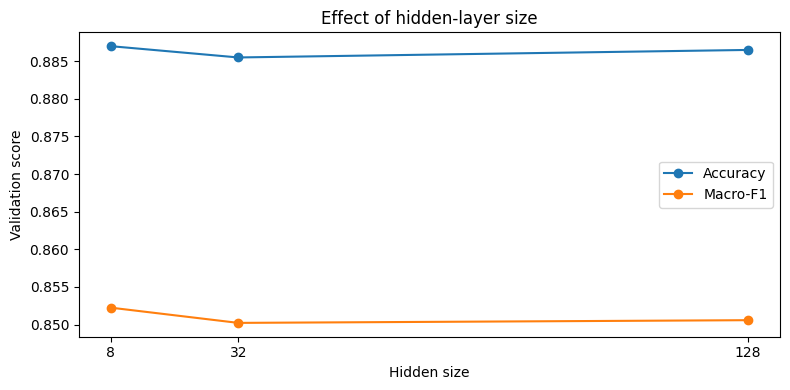

In [11]:
# Compare hidden sizes using the selected learning rate
hidden_size_results = [{
    "run": "hidden_32_baseline",
    "learning_rate": 1e-3,
    "hidden_size": 32,
    "batch_size": 64,
    "validation_accuracy":
        baseline_validation_results["eval_accuracy"],
    "validation_macro_f1":
        baseline_validation_results["eval_macro_f1"],
    "best_epoch": baseline_best_log["epoch"],
    "epochs_completed": baseline_trainer.state.epoch,
    "training_minutes": baseline_training_time / 60,
    "training_steps": baseline_train_output.global_step
}]

for hidden_size in [8, 128]:
    result = run_experiment(
        run_name=f"hidden_{hidden_size}",
        learning_rate=1e-3,
        hidden_size=hidden_size,
        batch_size=64
    )

    hidden_size_results.append(result)

hidden_size_df = pd.DataFrame(
    hidden_size_results
).sort_values("hidden_size")

display(
    hidden_size_df[
        [
            "hidden_size",
            "validation_accuracy",
            "validation_macro_f1",
            "best_epoch",
            "epochs_completed",
            "training_minutes"
        ]
    ].round(4)
)

plt.figure(figsize=(8, 4))

plt.plot(
    hidden_size_df["hidden_size"],
    hidden_size_df["validation_accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    hidden_size_df["hidden_size"],
    hidden_size_df["validation_macro_f1"],
    marker="o",
    label="Macro-F1"
)

plt.xlabel("Hidden size")
plt.ylabel("Validation score")
plt.title("Effect of hidden-layer size")
plt.xticks(hidden_size_df["hidden_size"])
plt.legend()
plt.tight_layout()
plt.show()

Increasing the hidden size did not improve the validation result. The smallest hidden size of 8 achieved the highest macro-F1 of 0.8523. The differences were small, but the larger models used many more parameters without producing better performance. This suggests that a small hidden representation is already sufficient for this dataset. I selected a hidden size of 8 for the batch-size experiment.

{'eval_loss': '1.026', 'eval_accuracy': '0.6615', 'eval_macro_f1': '0.4198', 'eval_runtime': '0.2877', 'eval_samples_per_second': '6951', 'eval_steps_per_second': '55.6', 'epoch': '1'}
{'eval_loss': '0.5009', 'eval_accuracy': '0.8685', 'eval_macro_f1': '0.8214', 'eval_runtime': '0.1652', 'eval_samples_per_second': '1.211e+04', 'eval_steps_per_second': '96.86', 'epoch': '2'}
{'eval_loss': '0.3637', 'eval_accuracy': '0.8845', 'eval_macro_f1': '0.8494', 'eval_runtime': '0.1608', 'eval_samples_per_second': '1.243e+04', 'eval_steps_per_second': '99.47', 'epoch': '3'}
{'eval_loss': '0.3379', 'eval_accuracy': '0.8875', 'eval_macro_f1': '0.851', 'eval_runtime': '0.2898', 'eval_samples_per_second': '6902', 'eval_steps_per_second': '55.22', 'epoch': '4'}
{'eval_loss': '0.3398', 'eval_accuracy': '0.8905', 'eval_macro_f1': '0.8568', 'eval_runtime': '0.1624', 'eval_samples_per_second': '1.231e+04', 'eval_steps_per_second': '98.5', 'epoch': '5'}
{'eval_loss': '0.356', 'eval_accuracy': '0.888', 'eval

,batch_size,validation_accuracy,validation_macro_f1,best_epoch,epochs_completed,training_minutes
1,16,0.891,0.8607,8.0,11.0,0.8082
0,64,0.887,0.8523,9.0,12.0,0.4360
2,256,0.858,0.8081,18.0,20.0,0.6407


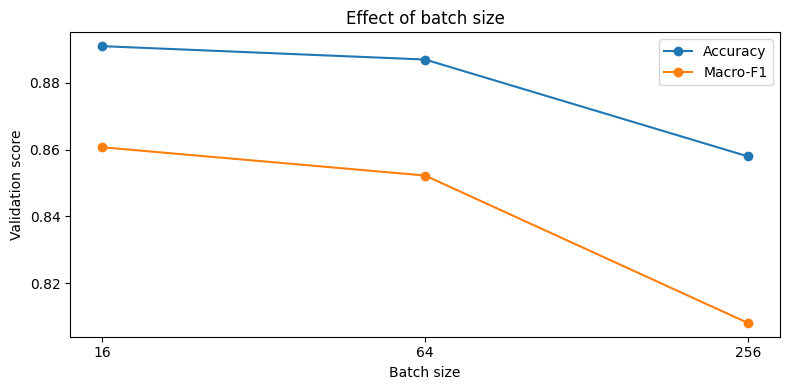

In [12]:
# Reuse the completed hidden-size-8 result for batch size 64
selected_hidden_result = (
    hidden_size_df[
        hidden_size_df["hidden_size"] == 8
    ]
    .iloc[0]
    .to_dict()
)

batch_size_results = [selected_hidden_result]

# Compare a small and a large batch with the current batch size
for batch_size in [16, 256]:
    result = run_experiment(
        run_name=f"batch_{batch_size}",
        learning_rate=1e-3,
        hidden_size=8,
        batch_size=batch_size
    )

    batch_size_results.append(result)

batch_size_df = pd.DataFrame(
    batch_size_results
).sort_values("batch_size")

display(
    batch_size_df[
        [
            "batch_size",
            "validation_accuracy",
            "validation_macro_f1",
            "best_epoch",
            "epochs_completed",
            "training_minutes"
        ]
    ].round(4)
)

plt.figure(figsize=(8, 4))

plt.plot(
    batch_size_df["batch_size"],
    batch_size_df["validation_accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    batch_size_df["batch_size"],
    batch_size_df["validation_macro_f1"],
    marker="o",
    label="Macro-F1"
)

plt.xscale("log", base=2)
plt.xticks(
    batch_size_df["batch_size"],
    batch_size_df["batch_size"]
)

plt.xlabel("Batch size")
plt.ylabel("Validation score")
plt.title("Effect of batch size")
plt.legend()
plt.tight_layout()
plt.show()

The batch size also affected the results. A batch size of 16 achieved the highest validation accuracy and macro-F1, although it took longer to train because it required more parameter updates. A batch size of 64 was faster but slightly weaker. The largest batch size of 256 learned much more slowly and produced the lowest result within the 20-epoch limit. I therefore selected a batch size of 16.

Based on all three experiments, the final configuration used a learning rate of 0.001, a hidden size of 8, and a batch size of 16.

### 3.3. Evaluation on test set

After selecting all hyperparameters using the validation set, I trained a fresh model with the selected configuration. The model with the best validation macro-F1 was then evaluated once on the official test set. The test set was not used during model selection.

In [13]:
# Final selected hyperparameters
FINAL_LEARNING_RATE = 1e-3
FINAL_HIDDEN_SIZE = 8
FINAL_BATCH_SIZE = 16
FINAL_MAX_EPOCHS = 20

# Reset seeds before final training
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Create a fresh final model
final_model = EmotionMLP(
    vocab_size=len(tokenizer),
    hidden_size=FINAL_HIDDEN_SIZE,
    num_labels=len(label_names),
    padding_idx=tokenizer.pad_token_id
)

final_parameter_count = sum(
    parameter.numel()
    for parameter in final_model.parameters()
)

print(
    f"Final model trainable parameters: "
    f"{final_parameter_count:,}"
)

final_training_args = TrainingArguments(
    output_dir="final_model_checkpoints",
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    learning_rate=FINAL_LEARNING_RATE,
    num_train_epochs=FINAL_MAX_EPOCHS,
    per_device_train_batch_size=FINAL_BATCH_SIZE,
    per_device_eval_batch_size=128,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=1,
    seed=SEED,
    data_seed=SEED,
    report_to="none"
)

final_trainer = Trainer(
    model=final_model,
    args=final_training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=3
        )
    ]
)

final_start_time = time.time()

final_train_output = final_trainer.train()

final_training_time = time.time() - final_start_time

# Confirm the selected model's validation performance
final_validation_results = final_trainer.evaluate()

# Evaluate once on the untouched official test set
test_output = final_trainer.predict(
    tokenized_dataset["test"]
)

test_logits = test_output.predictions

if isinstance(test_logits, tuple):
    test_logits = test_logits[0]

test_predictions = np.argmax(
    test_logits,
    axis=-1
)

test_labels = test_output.label_ids

print("\nFinal selected configuration:")
print(f"Learning rate: {FINAL_LEARNING_RATE}")
print(f"Hidden size: {FINAL_HIDDEN_SIZE}")
print(f"Batch size: {FINAL_BATCH_SIZE}")

print("\nFinal validation results:")
print(
    f"Accuracy: "
    f"{final_validation_results['eval_accuracy']:.4f}"
)
print(
    f"Macro-F1: "
    f"{final_validation_results['eval_macro_f1']:.4f}"
)

print("\nOfficial test results:")
print(
    f"Accuracy: "
    f"{test_output.metrics['test_accuracy']:.4f}"
)
print(
    f"Macro-F1: "
    f"{test_output.metrics['test_macro_f1']:.4f}"
)
print(
    f"Test loss: "
    f"{test_output.metrics['test_loss']:.4f}"
)
print(
    f"Final training time: "
    f"{final_training_time / 60:.2f} minutes"
)
print(
    f"Training steps: "
    f"{final_train_output.global_step}"
)

Final model trainable parameters: 120,054


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.366366,1.026034,0.661500,0.419792
2,0.606688,0.500919,0.868500,0.821357
3,0.236677,0.363662,0.884500,0.849372
4,0.130899,0.337927,0.887500,0.850995
5,0.087928,0.339827,0.890500,0.856828
6,0.064783,0.355977,0.888000,0.853737
7,0.050263,0.372332,0.889500,0.857409
8,0.039995,0.384709,0.891000,0.860714
9,0.032972,0.402564,0.887000,0.854220
10,0.028184,0.426667,0.882500,0.851554


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
0.024336,0.384709,11,0.891000,0.860714



Final selected configuration:
Learning rate: 0.001
Hidden size: 8
Batch size: 16

Final validation results:
Accuracy: 0.8910
Macro-F1: 0.8607

Official test results:
Accuracy: 0.8715
Macro-F1: 0.8235
Test loss: 0.3977
Final training time: 0.79 minutes
Training steps: 11000


The selected model achieved an accuracy of 0.8715 and a macro-F1 of 0.8235 on the official test set. Both scores were lower than the validation results, which suggests that the test examples were slightly more difficult for the model. The test macro-F1 was also lower than the accuracy, indicating that the model did not perform equally well across all six emotion classes. I examined the per-class results and confusion matrix below.

,precision,recall,f1-score,support
sadness,0.9209,0.9019,0.9113,581.0
joy,0.8802,0.9194,0.8994,695.0
love,0.7134,0.7044,0.7089,159.0
anger,0.8843,0.8618,0.8729,275.0
fear,0.8493,0.8304,0.8397,224.0
surprise,0.7377,0.6818,0.7087,66.0


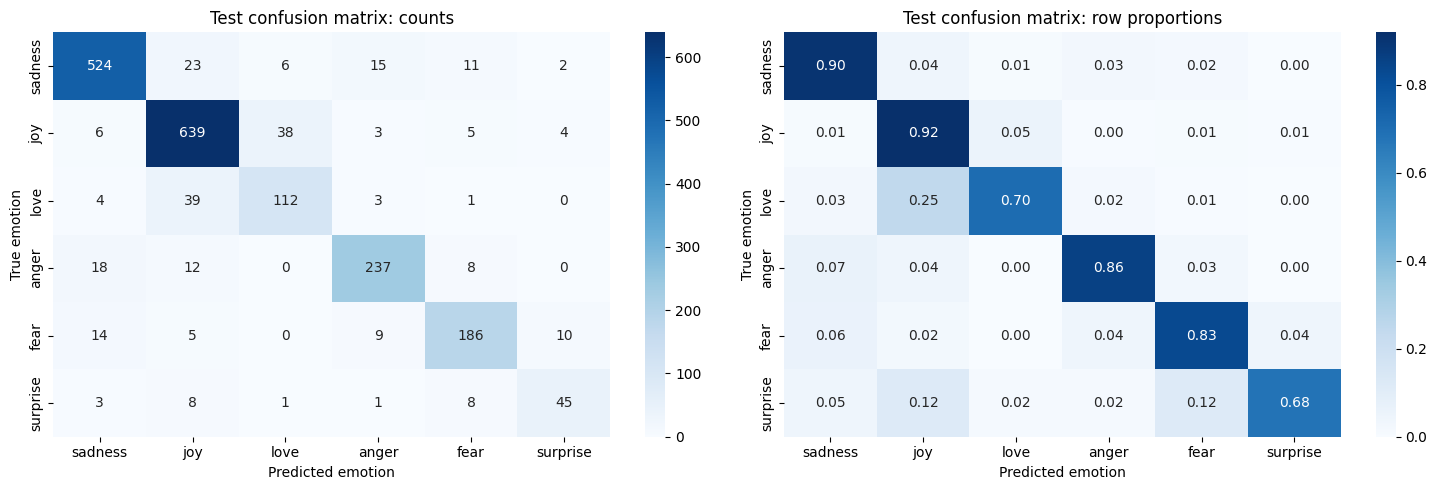

In [14]:
# Per-class precision, recall and F1
test_classification_report = classification_report(
    test_labels,
    test_predictions,
    labels=list(range(len(label_names))),
    target_names=label_names,
    output_dict=True,
    zero_division=0
)

per_class_results_df = pd.DataFrame(
    test_classification_report
).transpose().loc[label_names]

display(
    per_class_results_df[
        ["precision", "recall", "f1-score", "support"]
    ].round(4)
)

# Raw and row-normalized confusion matrices
test_confusion_matrix = confusion_matrix(
    test_labels,
    test_predictions,
    labels=list(range(len(label_names)))
)

normalized_confusion_matrix = confusion_matrix(
    test_labels,
    test_predictions,
    labels=list(range(len(label_names))),
    normalize="true"
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5)
)

sns.heatmap(
    test_confusion_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_names,
    yticklabels=label_names,
    ax=axes[0]
)

axes[0].set_title("Test confusion matrix: counts")
axes[0].set_xlabel("Predicted emotion")
axes[0].set_ylabel("True emotion")

sns.heatmap(
    normalized_confusion_matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=label_names,
    yticklabels=label_names,
    ax=axes[1]
)

axes[1].set_title("Test confusion matrix: row proportions")
axes[1].set_xlabel("Predicted emotion")
axes[1].set_ylabel("True emotion")

plt.tight_layout()
plt.show()

The model performed best on sadness and joy, which were also the two largest classes. Love and surprise had the lowest F1-scores. The clearest confusion was between love and joy: 39 of the 159 love examples were predicted as joy. These emotions can share positive words, which may make them difficult for a model that mainly uses token-level signals.

Surprise was confused with both joy and fear. Eight surprise examples were predicted as joy and another eight as fear. This seems reasonable because surprise can be either positive or frightening depending on the situation. Anger and fear were also occasionally predicted as sadness. Overall, the model learned the main differences between the emotions, but it had more difficulty with related or overlapping emotions and with classes that had fewer training examples.

In [15]:
# Convert logits into predicted probabilities
test_probabilities = torch.softmax(
    torch.tensor(test_logits),
    dim=1
).numpy()

error_rows = []

for index, (
    text,
    true_label,
    predicted_label
) in enumerate(
    zip(
        dataset["test"]["text"],
        test_labels,
        test_predictions
    )
):
    if true_label != predicted_label:
        error_rows.append({
            "index": index,
            "text": text,
            "true_emotion": id2label[int(true_label)],
            "predicted_emotion":
                id2label[int(predicted_label)],
            "prediction_confidence":
                test_probabilities[
                    index,
                    predicted_label
                ]
        })

errors_df = pd.DataFrame(error_rows)

print(
    f"Misclassified test examples: "
    f"{len(errors_df)} out of {len(test_labels)}"
)

# Show the most frequent confusion pairs
confusion_pairs_df = (
    errors_df
    .groupby(
        ["true_emotion", "predicted_emotion"]
    )
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

display(confusion_pairs_df.head(10))

# Inspect two examples from each important confusion
important_confusions = [
    ("love", "joy"),
    ("surprise", "joy"),
    ("surprise", "fear"),
    ("anger", "sadness"),
    ("fear", "sadness")
]

selected_error_examples = []

for true_emotion, predicted_emotion in important_confusions:
    subset = errors_df[
        (errors_df["true_emotion"] == true_emotion)
        & (
            errors_df["predicted_emotion"]
            == predicted_emotion
        )
    ]

    # Select confident errors to see which examples
    # most strongly misled the model
    subset = subset.sort_values(
        "prediction_confidence",
        ascending=False
    ).head(2)

    selected_error_examples.append(subset)

selected_errors_df = pd.concat(
    selected_error_examples,
    ignore_index=True
)

Misclassified test examples: 257 out of 2000


,true_emotion,predicted_emotion,count
14,love,joy,39
9,joy,love,38
18,sadness,joy,23
2,anger,sadness,18
16,sadness,anger,15
5,fear,sadness,14
1,anger,joy,12
17,sadness,fear,11
6,fear,surprise,10
3,fear,anger,9


In [16]:
# Display complete error texts without truncation
with pd.option_context(
    "display.max_colwidth",
    None,
    "display.max_rows",
    None
):
    display(
        selected_errors_df[
            [
                "text",
                "true_emotion",
                "predicted_emotion",
                "prediction_confidence"
            ]
        ].round({
            "prediction_confidence": 4
        })
    )


,text,true_emotion,predicted_emotion,prediction_confidence
0,i must add the crowd was similar to last night except it had a much more laid back stoner feel with supporting cast of parents escaped from their kids,love,joy,0.9915
1,ive been feeling from my adoring fans that would be teh whole like of you who are my friends here i felt brave and excited and ventrured forth with guitar in hand to a local open mic night,love,joy,0.9897
2,i will practice meditation if i feel overwhelmed and hopefully become successful in peaceful practice,surprise,joy,0.9994
3,i know it can take weeks for a book to go free on amazon and barnes amp noble and in this age where cents can buy a full length ebook i feel a little funny charging even cents for a work that is almost certain to be under pages possibly under,surprise,joy,0.9938
4,i feel so weird and scattered with all wonders about a million different things,surprise,fear,0.9808
5,i was so uncomfortable and feeling weird feelings but wasn t sure if they were contractions since i never really felt contractions with jared until they jacked me up with pitocin,surprise,fear,0.9755
6,i had to continue to enforce my no playdate policy which meant i continued to feel angry twice over each day once during a horrible morning drop off and once in the afternoon when i reminded noah that no he couldnt play because of the bad drop off missing mommy,anger,sadness,0.9992
7,i really dont like quinn because i feel like she will just end up hurting barney and i hated the lame ted robin storyline,anger,sadness,0.9852
8,i am truly unfortunate the majority of the time i m usually drained but i obtain it hard to get from bed i really feel restless and others,fear,sadness,1.0000
9,i see you on the pitchers mound at our little league diamond i feel so anxious for you because it looks so isolated over there,fear,sadness,0.9999


I manually inspected some of the most confident errors. Several examples contained words connected to more than one emotion. For example, a love example included “brave and excited,” which gives the model a strong reason to predict joy. The surprise examples predicted as fear included words such as “overwhelmed,” “weird,” and “uncomfortable.” Similarly, one fear example described feeling unfortunate, drained, and unable to get out of bed, which also sounds similar to sadness.

Some examples were also difficult for me to assign to the original label based only on the text. For example, the first love example did not contain a clear expression of love. This suggests that part of the difficulty may come from ambiguous or noisy annotations, not only from the model. The MLP also adds the token embeddings together, so it cannot fully represent word order or which emotional cue is most important in context. Strong individual words may therefore cause a confident but incorrect prediction.

---

## 4. Results and summary

### 4.1 Corpus insights

The Emotion corpus contains short English texts labelled with six emotions: anger, fear, joy, love, sadness, and surprise. The original training, validation, and test splits were already provided, so I kept them unchanged. The class distribution is not balanced, with sadness and joy occurring more often than love and surprise.

While examining the data and the model errors, I also noticed that some texts can reasonably express more than one emotion. For example, positive expressions may be difficult to separate between joy and love, while surprise can occur together with either positive or fearful language. Some examples were also difficult to interpret from the text alone. This suggests that emotion classification can contain some ambiguity even when each example is assigned only one label.


### 4.2 Results

The baseline model used a learning rate of 0.001, a hidden size of 32, and a batch size of 64, and achieved a validation macro-F1 of 0.8502. Hyperparameter experiments showed that the learning rate had the strongest effect on training. A learning rate of 0.001 performed best, while a smaller hidden size of 8 slightly improved the validation result. A batch size of 16 produced the best result among the tested batch sizes.

The final configuration therefore used a learning rate of 0.001, a hidden size of 8, and a batch size of 16. On the official test set, the final model achieved an accuracy of 0.8715 and a macro-F1 of 0.8235.

The model performed best on sadness and joy and had more difficulty with love and surprise. The error analysis showed that many mistakes occurred between emotions that can share similar words or meanings, especially joy and love. The relatively simple MLP representation also does not model word order directly, which may contribute to these errors.

### 4.3. Relation to state of the art

The final model achieved an accuracy of 0.8715 and a macro-F1 score of 0.8235 on the official test set. The fine-tuned LLaMA 3 model reported by Kermani et al. (2025) achieved 0.91 accuracy and 0.87 macro-F1 on the same dataset split. My model was therefore 3.85 percentage points lower in accuracy and 4.65 percentage points lower in macro-F1.

This difference is understandable because the reported comparison uses LLaMA 3 with approximately eight billion pretrained parameters. In comparison, my model is a small MLP with 120,054 trainable parameters, an eight-dimensional embedding layer and a tokenizer trained only on the provided training corpus. My model does not use pretrained language representations or external training data.

Even with this much smaller model, its performance on the original test set was reasonably close to the reported LLaMA 3 result. The model performed best for sadness and joy, while love and surprise were more difficult. This was also shown by their lower class-level F1 scores.

The comparison should still be treated carefully because the LLaMA 3 result comes from an arXiv preprint rather than an official maintained leaderboard. Although the same dataset and split sizes were used, there may also be differences in preprocessing and experimental setup between the two projects.





## 5. Bonus Task (optional)

### 5.1. Annotating out-of-domain documents

For the out-of-domain data, I chose sentences from five literary-fiction texts available through the NLTK Gutenberg corpus: *Emma*, *Alice's Adventures in Wonderland*, *The Wisdom of Father Brown*, *Moby-Dick* and *Hamlet*. These texts are different from the short and informal first-person texts in the original emotion dataset. The literary sentences are generally older, more formal and sometimes describe emotions indirectly, making them useful for testing how well the model works on a different type of text.

To find suitable annotation candidates, I first split the books into sentences. I then searched for sentences containing words related to the six emotion categories: sadness, joy, love, anger, fear and surprise. I kept sentences containing words from only one cue group and limited their length to between 8 and 45 words. The cue words were used only to find possible examples and did not automatically determine the final emotion label.

I shuffled the selected candidates and manually annotated them using the same six labels as the original dataset. I selected the emotion that was mainly expressed by the character, speaker or narrator. The cue group was not displayed while I was annotating because the same word can express different emotions depending on its context. I marked a sentence as `reject` when it was neutral, too ambiguous or required more context to understand.

After the first annotation round, some emotion classes had fewer accepted examples. I therefore selected and manually annotated additional candidates, especially for the less represented classes. After removing the rejected examples, the final out-of-domain test set contained 50 manually annotated sentences.

In [17]:
# Install and download the public-domain Gutenberg corpus
!pip install -q nltk

import re
import nltk

from nltk.corpus import gutenberg
from nltk.tokenize.treebank import TreebankWordDetokenizer

nltk.download("gutenberg", quiet=True)
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

detokenizer = TreebankWordDetokenizer()

# Public-domain literary works used for candidate collection
literary_sources = {
    "austen-emma.txt": {
        "title": "Emma",
        "author": "Jane Austen"
    },
    "carroll-alice.txt": {
        "title": "Alice's Adventures in Wonderland",
        "author": "Lewis Carroll"
    },
    "chesterton-brown.txt": {
        "title": "The Wisdom of Father Brown",
        "author": "G. K. Chesterton"
    },
    "melville-moby_dick.txt": {
        "title": "Moby-Dick",
        "author": "Herman Melville"
    },
    "shakespeare-hamlet.txt": {
        "title": "Hamlet",
        "author": "William Shakespeare"
    }
}

# These cues are used only to find possible emotional sentences.
# They are not used as automatic labels.
emotion_cues = {
    "sadness": {
        "sad", "sadness", "sorrow", "miserable",
        "unhappy", "grief", "grieve", "wept",
        "weep", "cry", "cried", "tears"
    },
    "joy": {
        "joy", "joyful", "happy", "happiness",
        "delight", "delighted", "pleased", "glad",
        "laugh", "laughed", "smile", "smiled",
        "excited"
    },
    "love": {
        "love", "loved", "lover", "loving",
        "affection", "adore", "adored", "beloved",
        "dear", "darling"
    },
    "anger": {
        "anger", "angry", "rage", "fury",
        "furious", "hate", "hated", "irritated",
        "annoyed", "resentment"
    },
    "fear": {
        "fear", "afraid", "frightened", "terrified",
        "anxious", "anxiety", "worry", "worried",
        "dread", "horror", "scared"
    },
    "surprise": {
        "surprise", "surprised", "astonished",
        "amazed", "wonder", "wondered",
        "unexpected", "unexpectedly", "suddenly"
    }
}

candidate_rows = []

for file_id, source_information in literary_sources.items():
    for sentence_tokens in gutenberg.sents(file_id):
        # Count actual word-like tokens
        word_tokens = [
            token for token in sentence_tokens
            if re.search(r"[A-Za-z]", token)
        ]

        # Keep sentences that are long enough to contain context
        # but short enough to annotate independently
        if not 8 <= len(word_tokens) <= 45:
            continue

        normalized_words = {
            re.sub(r"[^a-z']", "", token.lower())
            for token in sentence_tokens
        }

        matched_groups = [
            emotion
            for emotion, cues in emotion_cues.items()
            if normalized_words & cues
        ]

        # Keep sentences linked to exactly one preliminary cue group.
        # The final emotion will still be manually assigned.
        if len(matched_groups) != 1:
            continue

        text = detokenizer.detokenize(sentence_tokens)
        text = re.sub(r"\s+", " ", text).strip()

        candidate_rows.append({
            "text": text,
            "cue_group": matched_groups[0],
            "source_title": source_information["title"],
            "source_author": source_information["author"],
            "source_file": file_id
        })

candidate_pool_df = (
    pd.DataFrame(candidate_rows)
    .drop_duplicates(subset="text")
)

# Randomize candidates reproducibly
candidate_pool_df = candidate_pool_df.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)

print(
    f"Total candidate sentences: "
    f"{len(candidate_pool_df)}"
)

display(
    candidate_pool_df
    .groupby("cue_group")
    .size()
    .rename("candidate_count")
    .to_frame()
)

display(
    candidate_pool_df
    .groupby("source_title")
    .size()
    .rename("candidate_count")
    .to_frame()
)

Total candidate sentences: 1549


,candidate_count
cue_group,
anger,77
fear,207
joy,416
love,325
sadness,323
surprise,201


,candidate_count
source_title,
Alice's Adventures in Wonderland,123
Emma,787
Hamlet,27
Moby-Dick,370
The Wisdom of Father Brown,242


In [18]:
# Sample a manageable set of candidates for manual annotation
annotation_candidates = (
    candidate_pool_df
    .groupby("cue_group", group_keys=False)
    .apply(
        lambda group: group.sample(
            n=min(10, len(group)),
            random_state=SEED
        )
    )
    .reset_index(drop=True)
)

# Shuffle the annotation order so the cue group does not influence labelling
annotation_candidates = annotation_candidates.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)

annotation_candidates.insert(
    0,
    "annotation_id",
    range(1, len(annotation_candidates) + 1)
)

print(
    f"Sentences selected for manual annotation: "
    f"{len(annotation_candidates)}"
)

display(
    annotation_candidates[
        [
            "annotation_id",
            "text",
            "source_title",
            "source_author"
        ]
    ]
)

Sentences selected for manual annotation: 60


,annotation_id,text,source_title,source_author
0,1,"' Well, perhaps not,' said Alice in a soothing...",Alice's Adventures in Wonderland,Lewis Carroll
1,2,"Next instant, the luckless mate, so full of fu...",Moby-Dick,Herman Melville
2,3,My dear Miss Woodhouse--I come quite over - po...,Emma,Jane Austen
3,4,""" Do tell, now,"" cried Bildad, "" is this Phili...",Moby-Dick,Herman Melville
4,5,He had left them completely frightened; and Ha...,Emma,Jane Austen
5,6,An extraordinary expression flashed across her...,The Wisdom of Father Brown,G. K. Chesterton
6,7,"-- and "" Dear Miss Woodhouse,"" was all that Ha...",Emma,Jane Austen
7,8,"It made him so very unhappy, indeed, that it c...",Emma,Jane Austen
8,9,"""' Though there are no Auto - da - Fe' s in Li...",Moby-Dick,Herman Melville
9,10,John Knightley came; but Mr . Weston was unexp...,Emma,Jane Austen


In [19]:
# Print the complete sentences for manual annotation
for _, row in annotation_candidates.iterrows():
    print(f"ID {row['annotation_id']}")
    print(f"Source: {row['source_title']} — {row['source_author']}")
    print(row["text"])
    print("-" * 80)

ID 1
Source: Alice's Adventures in Wonderland — Lewis Carroll
' Well, perhaps not,' said Alice in a soothing tone:' don' t be angry about it.
--------------------------------------------------------------------------------
ID 2
Source: Moby-Dick — Herman Melville
Next instant, the luckless mate, so full of furious life, was smitten bodily into the air, and making a long arc in his descent, fell into the sea at the distance of about fifty yards.
--------------------------------------------------------------------------------
ID 3
Source: Emma — Jane Austen
My dear Miss Woodhouse--I come quite over - powered.
--------------------------------------------------------------------------------
ID 4
Source: Moby-Dick — Herman Melville
" Do tell, now," cried Bildad, " is this Philistine a regular member of Deacon Deuteronomy' s meeting?
--------------------------------------------------------------------------------
ID 5
Source: Emma — Jane Austen
He had left them completely frightened; and Har

In [20]:
# Store the finalized manual annotations for the first 60 candidates
manual_annotations = {
    1: "anger",
    2: "reject",
    3: "reject",
    4: "reject",
    5: "fear",
    6: "surprise",
    7: "love",
    8: "sadness",
    9: "reject",
    10: "surprise",
    11: "anger",
    12: "reject",
    13: "reject",
    14: "anger",
    15: "reject",
    16: "reject",
    17: "anger",
    18: "anger",
    19: "surprise",
    20: "anger",
    21: "anger",
    22: "sadness",
    23: "reject",
    24: "reject",
    25: "joy",
    26: "reject",
    27: "fear",
    28: "joy",
    29: "reject",
    30: "reject",
    31: "sadness",
    32: "reject",
    33: "joy",
    34: "surprise",
    35: "fear",
    36: "love",
    37: "reject",
    38: "reject",
    39: "joy",
    40: "joy",
    41: "reject",
    42: "anger",
    43: "joy",
    44: "anger",
    45: "reject",
    46: "love",
    47: "sadness",
    48: "anger",
    49: "surprise",
    50: "sadness",
    51: "reject",
    52: "reject",
    53: "reject",
    54: "joy",
    55: "reject",
    56: "reject",
    57: "joy",
    58: "sadness",
    59: "surprise",
    60: "love"
}

annotation_candidates["manual_label"] = (
    annotation_candidates["annotation_id"]
    .map(manual_annotations)
)

# Keep only sentences that received one of the six emotion labels
accepted_annotations = annotation_candidates[
    annotation_candidates["manual_label"] != "reject"
].copy()

print(
    f"Accepted sentences: {len(accepted_annotations)}"
)

print(
    f"Rejected sentences: "
    f"{(annotation_candidates['manual_label'] == 'reject').sum()}"
)

display(
    accepted_annotations["manual_label"]
    .value_counts()
    .reindex([
        "sadness",
        "joy",
        "love",
        "anger",
        "fear",
        "surprise"
    ])
    .rename("count")
    .to_frame()
)

Accepted sentences: 37
Rejected sentences: 23


,count
manual_label,
sadness,6
joy,8
love,4
anger,10
fear,3
surprise,6


In [21]:
# Select additional candidates that were not part of the first 60
used_texts = set(annotation_candidates["text"])

remaining_candidates = candidate_pool_df[
    ~candidate_pool_df["text"].isin(used_texts)
].copy()

# Prefer more fear and love candidates, since these classes are currently smaller
replacement_targets = {
    "fear": 8,
    "love": 8,
    "sadness": 4,
    "joy": 4,
    "anger": 4,
    "surprise": 4
}

replacement_parts = []

for cue_group, n_samples in replacement_targets.items():
    group = remaining_candidates[
        remaining_candidates["cue_group"] == cue_group
    ]

    sampled = group.sample(
        n=min(n_samples, len(group)),
        random_state=SEED
    )

    replacement_parts.append(sampled)

replacement_candidates = pd.concat(
    replacement_parts,
    ignore_index=True
)

# Shuffle so cue-group order does not influence manual annotation
replacement_candidates = replacement_candidates.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)

replacement_candidates.insert(
    0,
    "annotation_id",
    range(61, 61 + len(replacement_candidates))
)

print(
    f"Additional sentences selected: "
    f"{len(replacement_candidates)}"
)

for _, row in replacement_candidates.iterrows():
    print(f"ID {row['annotation_id']}")
    print(f"Source: {row['source_title']} — {row['source_author']}")
    print(row["text"])
    print("-" * 80)

Additional sentences selected: 32
ID 61
Source: The Wisdom of Father Brown — G. K. Chesterton
His friend looked at him in some surprise.
--------------------------------------------------------------------------------
ID 62
Source: Alice's Adventures in Wonderland — Lewis Carroll
Then again --" BEFORE SHE HAD THIS FIT --" you never had fits, my dear, I think?'
--------------------------------------------------------------------------------
ID 63
Source: Emma — Jane Austen
They must not do less than others, or she should be exposed to odious suspicions, and imagined capable of pitiful resentment.
--------------------------------------------------------------------------------
ID 64
Source: Moby-Dick — Herman Melville
cried Starbuck, " that simply smote thee from blindest instinct!
--------------------------------------------------------------------------------
ID 65
Source: Emma — Jane Austen
In the way of love, I am sure he does not.
----------------------------------------------------

In [22]:
# Store the finalized manual annotations for the additional candidates
additional_manual_annotations = {
    61: "surprise",
    62: "reject",
    63: "reject",
    64: "reject",
    65: "reject",
    66: "reject",
    67: "reject",
    68: "anger",
    69: "sadness",
    70: "fear",
    71: "reject",
    72: "reject",
    73: "reject",
    74: "reject",
    75: "reject",
    76: "joy",
    77: "fear",
    78: "fear",
    79: "anger",
    80: "fear",
    81: "joy",
    82: "reject",
    83: "joy",
    84: "joy",
    85: "reject",
    86: "love"
}

# Add the manual labels to the additional candidate dataframe
replacement_candidates["manual_label"] = (
    replacement_candidates["annotation_id"]
    .map(additional_manual_annotations)
)

# Keep only the manually accepted additional sentences
additional_accepted = replacement_candidates[
    replacement_candidates["manual_label"].isin(
        ["sadness", "joy", "love", "anger", "fear", "surprise"]
    )
].copy()

# We only annotated through ID 86
additional_accepted = additional_accepted[
    additional_accepted["annotation_id"] <= 86
].copy()

print(f"Additional accepted sentences: {len(additional_accepted)}")

display(
    additional_accepted[
        [
            "annotation_id",
            "text",
            "manual_label",
            "source_title"
        ]
    ]
)

Additional accepted sentences: 13


,annotation_id,text,manual_label,source_title
0,61,His friend looked at him in some surprise.,surprise,The Wisdom of Father Brown
7,68,Should any unwarrantably pert young Leviathan ...,anger,Moby-Dick
8,69,He thought principally of Mrs . Churchill' s i...,sadness,Emma
9,70,Regent Street is not unknown to Lascars and Ma...,fear,Moby-Dick
15,76,""" They are all at me here that the fellow was ...",joy,The Wisdom of Father Brown
16,77,The error has been all my own; and I do assure...,fear,Emma
17,78,"The day approached, the day arrived; and after...",fear,Emma
18,79,If she could not have been angry with Frank Ch...,anger,Emma
19,80,"He searched all the outer salons; then, rememb...",fear,The Wisdom of Father Brown
20,81,I am very glad to see you: good euen Sir.,joy,Hamlet


### 5.2. Conversion into dataset

I combined the accepted examples from both annotation rounds and converted the manually written emotion labels into the same numerical label IDs used by the original corpus. I also kept the source information so that the origin of each example can be checked.

In [23]:
# Combine the accepted examples from both annotation rounds
final_ood_df = pd.concat(
    [accepted_annotations, additional_accepted],
    ignore_index=True
)

# Keep the examples in their original annotation order
final_ood_df = (
    final_ood_df
    .sort_values("annotation_id")
    .reset_index(drop=True)
)

# Give the final documents simpler IDs
final_ood_df.insert(
    0,
    "document_id",
    [f"OOD_{i:02d}" for i in range(1, len(final_ood_df) + 1)]
)

# Make the column names clearer
final_ood_df = final_ood_df.rename(
    columns={
        "manual_label": "label_name",
        "cue_group": "selection_cue_group"
    }
)

# Convert text labels into the numerical labels used by the model
label2id = {
    label_name: label_id
    for label_id, label_name in id2label.items()
}

final_ood_df["label"] = (
    final_ood_df["label_name"]
    .map(label2id)
    .astype(int)
)

# Check that the final data is valid
assert len(final_ood_df) == 50
assert final_ood_df["label_name"].notna().all()
assert final_ood_df["label"].notna().all()
assert final_ood_df["document_id"].is_unique

print("Final number of out-of-domain documents:", len(final_ood_df))
print("\nFinal label distribution:")
display(
    final_ood_df["label_name"]
    .value_counts()
    .reindex(label_names, fill_value=0)
    .rename_axis("emotion")
    .reset_index(name="count")
)

# Convert the dataframe into a Hugging Face Dataset
ood_dataset = datasets.Dataset.from_pandas(
    final_ood_df[
        [
            "document_id",
            "text",
            "label",
            "label_name",
            "source_title",
            "source_author",
            "source_file",
            "selection_cue_group"
        ]
    ],
    preserve_index=False
)

print("\nOut-of-domain dataset:")
print(ood_dataset)

display(final_ood_df.head())

Final number of out-of-domain documents: 50

Final label distribution:


,emotion,count
0,sadness,7
1,joy,12
2,love,5
3,anger,12
4,fear,7
5,surprise,7



Out-of-domain dataset:
Dataset({
    features: ['document_id', 'text', 'label', 'label_name', 'source_title', 'source_author', 'source_file', 'selection_cue_group'],
    num_rows: 50
})


,document_id,annotation_id,text,selection_cue_group,source_title,source_author,source_file,label_name,label
0,OOD_01,1,"' Well, perhaps not,' said Alice in a soothing...",anger,Alice's Adventures in Wonderland,Lewis Carroll,carroll-alice.txt,anger,3
1,OOD_02,5,He had left them completely frightened; and Ha...,fear,Emma,Jane Austen,austen-emma.txt,fear,4
2,OOD_03,6,An extraordinary expression flashed across her...,surprise,The Wisdom of Father Brown,G. K. Chesterton,chesterton-brown.txt,surprise,5
3,OOD_04,7,"-- and "" Dear Miss Woodhouse,"" was all that Ha...",love,Emma,Jane Austen,austen-emma.txt,love,2
4,OOD_05,8,"It made him so very unhappy, indeed, that it c...",sadness,Emma,Jane Austen,austen-emma.txt,sadness,0


### 5.3. Model evaluation on out-of-domain test set

I evaluated the final selected model on the 50 manually annotated literary sentences. I used the same tokenizer, label mapping and trained model as in the original test-set evaluation. The model was not retrained or adjusted using the out-of-domain data.

In [24]:
# Tokenize the out-of-domain texts using the same tokenizer
def tokenize_ood_examples(batch):
    return tokenizer(
        batch["text"],
        truncation=True
    )

# Remove the descriptive columns from the tokenized dataset,
# but retain the numerical label for evaluation
ood_columns_to_remove = [
    column
    for column in ood_dataset.column_names
    if column != "label"
]

ood_tokenized_dataset = ood_dataset.map(
    tokenize_ood_examples,
    batched=True,
    remove_columns=ood_columns_to_remove
)

print(ood_tokenized_dataset)
print("\nExample tokenized item:")
print(ood_tokenized_dataset[0])

Map:   0%|          | 0/50 [00:00<?, ? examples/s]

Dataset({
    features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 50
})

Example tokenized item:
{'label': 3, 'input_ids': [2, 1, 492, 1, 2258, 136, 1, 1, 684, 7871, 85, 5, 9680, 4007, 1, 1, 226, 1, 24, 80, 875, 147, 99, 1, 3], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


In [25]:
# Evaluate the already trained final model
ood_prediction_output = final_trainer.predict(
    ood_tokenized_dataset
)

# Obtain the true and predicted labels
ood_true_labels = ood_prediction_output.label_ids
ood_predicted_labels = np.argmax(
    ood_prediction_output.predictions,
    axis=1
)

# Store the main evaluation results
ood_accuracy = ood_prediction_output.metrics["test_accuracy"]
ood_macro_f1 = ood_prediction_output.metrics["test_macro_f1"]
ood_loss = ood_prediction_output.metrics["test_loss"]

print("Out-of-domain test results:")
print(f"Accuracy: {ood_accuracy:.4f}")
print(f"Macro-F1: {ood_macro_f1:.4f}")
print(f"Test loss: {ood_loss:.4f}")
print(
    "Correct predictions:",
    int((ood_true_labels == ood_predicted_labels).sum()),
    "out of",
    len(ood_true_labels)
)

Out-of-domain test results:
Accuracy: 0.4000
Macro-F1: 0.3649
Test loss: 2.8522
Correct predictions: 20 out of 50


### 5.4 Bonus task results



Out-of-domain tokenization:
Content tokens: 1484
Unknown tokens: 241
Unknown-token percentage: 16.24%


,test_set,accuracy,macro_f1,number_of_examples
0,Original emotion test set,0.8715,0.8235,2000
1,Literary out-of-domain test set,0.4000,0.3649,50


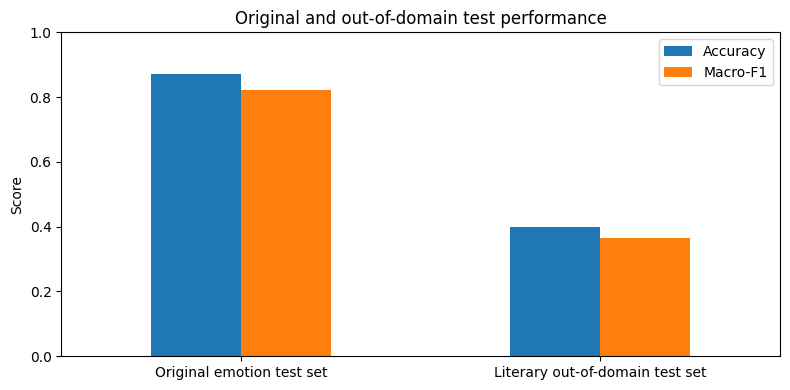

In [26]:
# Calculate the proportion of unknown tokens in the OOD dataset
unknown_token_id = tokenizer.unk_token_id

excluded_token_ids = {
    token_id
    for token_id in [
        tokenizer.pad_token_id,
        tokenizer.cls_token_id,
        tokenizer.sep_token_id
    ]
    if token_id is not None
}

ood_total_content_tokens = 0
ood_unknown_tokens = 0

for example in ood_tokenized_dataset:
    for token_id in example["input_ids"]:
        if token_id not in excluded_token_ids:
            ood_total_content_tokens += 1

            if token_id == unknown_token_id:
                ood_unknown_tokens += 1

ood_unknown_percentage = (
    100 * ood_unknown_tokens / ood_total_content_tokens
)

print("Out-of-domain tokenization:")
print("Content tokens:", ood_total_content_tokens)
print("Unknown tokens:", ood_unknown_tokens)
print(f"Unknown-token percentage: {ood_unknown_percentage:.2f}%")

# Compare performance on the original and out-of-domain test sets
test_comparison_df = pd.DataFrame({
    "test_set": [
        "Original emotion test set",
        "Literary out-of-domain test set"
    ],
    "accuracy": [
    test_output.metrics["test_accuracy"],
    ood_accuracy
    ],
    "macro_f1": [
    test_output.metrics["test_macro_f1"],
    ood_macro_f1
    ],
    "number_of_examples": [
        2000,
        50
    ]
})

display(test_comparison_df.round(4))

comparison_plot_df = test_comparison_df.set_index("test_set")[
    ["accuracy", "macro_f1"]
]

comparison_plot_df.plot(
    kind="bar",
    figsize=(8, 4),
    ylim=(0, 1),
    rot=0
)

plt.ylabel("Score")
plt.xlabel("")
plt.title("Original and out-of-domain test performance")
plt.legend(["Accuracy", "Macro-F1"])
plt.tight_layout()
plt.show()

,precision,recall,f1-score,support
sadness,0.2727,0.4286,0.3333,7.0
joy,0.3810,0.6667,0.4848,12.0
love,1.0000,0.4000,0.5714,5.0
anger,0.5000,0.3333,0.4000,12.0
fear,0.3750,0.4286,0.4000,7.0
surprise,0.0000,0.0000,0.0000,7.0


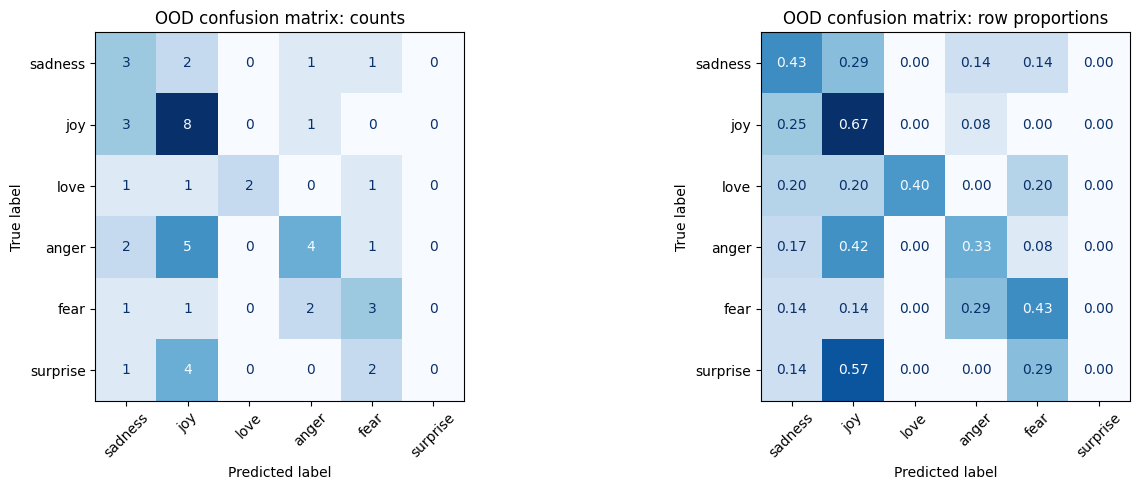

In [27]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

ood_report = classification_report(
    ood_true_labels,
    ood_predicted_labels,
    labels=list(range(len(label_names))),
    target_names=label_names,
    output_dict=True,
    zero_division=0
)

ood_report_df = pd.DataFrame(ood_report).transpose()

display(
    ood_report_df.loc[
        label_names,
        ["precision", "recall", "f1-score", "support"]
    ].round(4)
)

# Count and row-normalized confusion matrices
ood_cm_counts = confusion_matrix(
    ood_true_labels,
    ood_predicted_labels,
    labels=list(range(len(label_names)))
)

ood_cm_normalized = confusion_matrix(
    ood_true_labels,
    ood_predicted_labels,
    labels=list(range(len(label_names))),
    normalize="true"
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay(
    confusion_matrix=ood_cm_counts,
    display_labels=label_names
).plot(
    ax=axes[0],
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

axes[0].set_title("OOD confusion matrix: counts")
axes[0].tick_params(axis="x", rotation=45)

ConfusionMatrixDisplay(
    confusion_matrix=ood_cm_normalized,
    display_labels=label_names
).plot(
    ax=axes[1],
    cmap="Blues",
    colorbar=False,
    values_format=".2f"
)

axes[1].set_title("OOD confusion matrix: row proportions")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [28]:
# Convert logits into probabilities
ood_probabilities = torch.softmax(
    torch.tensor(ood_prediction_output.predictions),
    dim=1
).numpy()

# Add model outputs to the final annotated dataframe
final_ood_df["predicted_label"] = [
    id2label[int(label_id)]
    for label_id in ood_predicted_labels
]

final_ood_df["prediction_confidence"] = (
    ood_probabilities.max(axis=1)
)

final_ood_df["correct_prediction"] = (
    ood_true_labels == ood_predicted_labels
)

print(
    "Misclassified out-of-domain examples:",
    int((~final_ood_df["correct_prediction"]).sum()),
    "out of",
    len(final_ood_df)
)

display(
    final_ood_df[
        [
            "document_id",
            "text",
            "label_name",
            "predicted_label",
            "prediction_confidence",
            "source_title"
        ]
    ].style.format({
        "prediction_confidence": "{:.4f}"
    })
)

Misclassified out-of-domain examples: 30 out of 50


,document_id,text,label_name,predicted_label,prediction_confidence,source_title
0,OOD_01,"' Well, perhaps not,' said Alice in a soothing tone:' don' t be angry about it.",anger,anger,0.5482,Alice's Adventures in Wonderland
1,OOD_02,"He had left them completely frightened; and Harriet eagerly clinging to him, and hardly able to speak, had just strength enough to reach Hartfield, before her spirits were quite overcome.",fear,fear,0.9858,Emma
2,OOD_03,"An extraordinary expression flashed across her face, very different from pity, modesty, remorse, or anything her companion had expected: her voice became suddenly strong and full.",surprise,joy,0.9904,The Wisdom of Father Brown
3,OOD_04,"-- and "" Dear Miss Woodhouse,"" was all that Harriet, with many tender embraces could articulate at first; but when they did arrive at something more like conversation, it was sufficiently clear to her friend that she saw, felt, anticipated, and remembered just as she ought.",love,love,0.9952,Emma
4,OOD_05,"It made him so very unhappy, indeed, that it could not be persevered in.",sadness,sadness,0.9942,Emma
5,OOD_06,John Knightley came; but Mr . Weston was unexpectedly summoned to town and must be absent on the very day.,surprise,joy,0.9852,Emma
6,OOD_07,"cried Stubb, "" I knew it--ye can' t escape--blow on and split your spout, O whale!",anger,joy,0.8853,Moby-Dick
7,OOD_08,"said Alice, swallowing down her anger as well as she could.",anger,joy,0.5030,Alice's Adventures in Wonderland
8,OOD_09,"Angry as she was, the thought of the moment made her resolve to restrain herself when she did speak.",anger,anger,0.9876,Emma
9,OOD_10,"Towards thee I roll, thou all - destroying but unconquering whale; to the last I grapple with thee; from hell' s heart I stab at thee; for hate' s sake I spit my last breath at thee.",anger,anger,0.9997,Moby-Dick


The model performed considerably worse on the literary out-of-domain data than on the original test set. Its accuracy decreased from 0.8715 to 0.4000, while macro-F1 decreased from 0.8235 to 0.3649. It correctly classified 20 of the 50 literary sentences.

The performance also varied between the emotion classes. Joy had the highest recall at 0.6667, although its precision was only 0.3810 because the model predicted joy for many examples belonging to other classes. Love had the highest precision, but only two of the five love examples were detected. The model did not correctly classify any of the seven surprise examples and did not predict the surprise label at all. Most surprise examples were instead classified as joy or fear.

One possible reason for the lower performance is the difference between the two domains. The original corpus mainly contains short and informal first-person statements, while the out-of-domain data contains longer literary sentences, older vocabulary and emotions that are sometimes expressed indirectly. The tokenizer also produced 241 unknown tokens out of 1,484 content tokens, giving an unknown-token rate of 16.24%. In comparison, the original test data had no unknown tokens. This loss of vocabulary information probably contributed to the lower results, although it is not the only reason.

Some incorrect predictions were made with very high confidence. For example, several literary sentences were misclassified with confidence above 0.98. This suggests that the confidence scores of this model are not necessarily reliable when the input is different from its training data.

These results should still be interpreted carefully because the out-of-domain test set contains only 50 examples and the classes are not perfectly balanced. The texts also come mainly from a small collection of literary works, especially *Emma*, and the annotation was completed by one person. Even with these limitations, the experiment shows that strong performance on the original test set does not guarantee equally strong performance on a different style of language.

### 5.5. Annotated data

The table below contains the 50 manually annotated out-of-domain documents. The numerical labels follow the same mapping as the original emotion corpus.

In [29]:
 # Prepare the manually annotated data for inclusion in the notebook
annotated_ood_data = final_ood_df[
    [
        "document_id",
        "text",
        "label_name",
        "label",
        "source_title",
        "source_author",
        "source_file"
    ]
].copy()

print("Number of annotated documents:", len(annotated_ood_data))

display(
    annotated_ood_data.style.set_properties(
        subset=["text"],
        **{
            "white-space": "normal",
            "text-align": "left",
            "min-width": "500px"
        }
    )
)

# Save a separate copy of the annotations
annotated_ood_data.to_csv(
    "apurva_ood_emotion_annotations.csv",
    index=False
)

print(
    "\nSaved annotated data as:",
    "apurva_ood_emotion_annotations.csv"
)

Number of annotated documents: 50


,document_id,text,label_name,label,source_title,source_author,source_file
0,OOD_01,"' Well, perhaps not,' said Alice in a soothing tone:' don' t be angry about it.",anger,3,Alice's Adventures in Wonderland,Lewis Carroll,carroll-alice.txt
1,OOD_02,"He had left them completely frightened; and Harriet eagerly clinging to him, and hardly able to speak, had just strength enough to reach Hartfield, before her spirits were quite overcome.",fear,4,Emma,Jane Austen,austen-emma.txt
2,OOD_03,"An extraordinary expression flashed across her face, very different from pity, modesty, remorse, or anything her companion had expected: her voice became suddenly strong and full.",surprise,5,The Wisdom of Father Brown,G. K. Chesterton,chesterton-brown.txt
3,OOD_04,"-- and "" Dear Miss Woodhouse,"" was all that Harriet, with many tender embraces could articulate at first; but when they did arrive at something more like conversation, it was sufficiently clear to her friend that she saw, felt, anticipated, and remembered just as she ought.",love,2,Emma,Jane Austen,austen-emma.txt
4,OOD_05,"It made him so very unhappy, indeed, that it could not be persevered in.",sadness,0,Emma,Jane Austen,austen-emma.txt
5,OOD_06,John Knightley came; but Mr . Weston was unexpectedly summoned to town and must be absent on the very day.,surprise,5,Emma,Jane Austen,austen-emma.txt
6,OOD_07,"cried Stubb, "" I knew it--ye can' t escape--blow on and split your spout, O whale!",anger,3,Moby-Dick,Herman Melville,melville-moby_dick.txt
7,OOD_08,"said Alice, swallowing down her anger as well as she could.",anger,3,Alice's Adventures in Wonderland,Lewis Carroll,carroll-alice.txt
8,OOD_09,"Angry as she was, the thought of the moment made her resolve to restrain herself when she did speak.",anger,3,Emma,Jane Austen,austen-emma.txt
9,OOD_10,"Towards thee I roll, thou all - destroying but unconquering whale; to the last I grapple with thee; from hell' s heart I stab at thee; for hate' s sake I spit my last breath at thee.",anger,3,Moby-Dick,Herman Melville,melville-moby_dick.txt



Saved annotated data as: apurva_ood_emotion_annotations.csv


---

## 6. Pretrained transformer comparison

The custom MLP learns all of its parameters from the emotion training set. To
measure the value of transfer learning, I now fine-tune `distilbert-base-uncased`
on exactly the same official splits. DistilBERT is a compact pretrained
transformer, but it is still much larger than the MLP. The comparison therefore
considers model size and training time as well as predictive performance.

The transformer is selected using validation macro-F1. The official test set is
evaluated only after training and model selection are complete.


In [30]:
from transformers import AutoModelForSequenceClassification
import gc

TRANSFORMER_CHECKPOINT = "distilbert-base-uncased"
TRANSFORMER_MAX_LENGTH = 96

# Release unused cached tensors before loading the larger model.
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

transformer_tokenizer = AutoTokenizer.from_pretrained(
    TRANSFORMER_CHECKPOINT,
    use_fast=True
)


def tokenize_for_transformer(batch):
    return transformer_tokenizer(
        batch["text"],
        truncation=True,
        max_length=TRANSFORMER_MAX_LENGTH
    )


transformer_dataset = dataset.map(
    tokenize_for_transformer,
    batched=True,
    remove_columns=["text"]
)

transformer_data_collator = DataCollatorWithPadding(
    tokenizer=transformer_tokenizer
)

print(transformer_dataset)
print("Checkpoint:", TRANSFORMER_CHECKPOINT)
print("Maximum sequence length:", TRANSFORMER_MAX_LENGTH)


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/16000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 2000
    })
})
Checkpoint: distilbert-base-uncased
Maximum sequence length: 96


### 6.1 Fine-tuning setup

I use a learning rate of `2e-5`, weight decay of `0.01`, and a maximum of four epochs. Early stopping ends training
if validation macro-F1 does not improve for two evaluations. These are standard
fine-tuning choices rather than an extensive test-set-driven search.


In [32]:
# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

transformer_model = AutoModelForSequenceClassification.from_pretrained(
    TRANSFORMER_CHECKPOINT,
    num_labels=len(label_names),
    id2label=id2label,
    label2id=label2id
)

transformer_parameter_count = sum(
    parameter.numel()
    for parameter in transformer_model.parameters()
    if parameter.requires_grad
)

TRANSFORMER_LEARNING_RATE = 2e-5
TRANSFORMER_BATCH_SIZE = 16
TRANSFORMER_MAX_EPOCHS = 4

transformer_training_args = TrainingArguments(
    output_dir="distilbert_checkpoints",
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    learning_rate=TRANSFORMER_LEARNING_RATE,
    weight_decay=0.01,
    num_train_epochs=TRANSFORMER_MAX_EPOCHS,
    per_device_train_batch_size=TRANSFORMER_BATCH_SIZE,
    per_device_eval_batch_size=64,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=1,
    seed=SEED,
    data_seed=SEED,
    fp16=torch.cuda.is_available(),
    report_to="none"
)

transformer_trainer = Trainer(
    model=transformer_model,
    args=transformer_training_args,
    train_dataset=transformer_dataset["train"],
    eval_dataset=transformer_dataset["validation"],
    data_collator=transformer_data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
)

print(f"Trainable parameters: {transformer_parameter_count:,}")
print("Training device:", transformer_training_args.device)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainable parameters: 66,958,086
Training device: cuda:0


In [34]:
transformer_start_time = time.time()
transformer_train_output = transformer_trainer.train()
transformer_training_time = time.time() - transformer_start_time

transformer_validation_results = transformer_trainer.evaluate()
transformer_test_output = transformer_trainer.predict(
    transformer_dataset["test"]
)

transformer_test_logits = transformer_test_output.predictions
if isinstance(transformer_test_logits, tuple):
    transformer_test_logits = transformer_test_logits[0]

transformer_test_predictions = np.argmax(
    transformer_test_logits,
    axis=-1
)
transformer_test_labels = transformer_test_output.label_ids

print("Validation results:")
print(
    f"Accuracy: {transformer_validation_results['eval_accuracy']:.4f}"
)
print(
    f"Macro-F1: {transformer_validation_results['eval_macro_f1']:.4f}"
)

print(
"Official test results:")
print(
    f"Accuracy: {transformer_test_output.metrics['test_accuracy']:.4f}"
)
print(
    f"Macro-F1: {transformer_test_output.metrics['test_macro_f1']:.4f}"
)
print(
    f"Loss: {transformer_test_output.metrics['test_loss']:.4f}"
)
print(
    f"Training time: {transformer_training_time / 60:.2f} minutes"
)


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.473824,0.196559,0.930000,0.903181
2,0.149464,0.159716,0.933500,0.907696
3,0.108984,0.163107,0.939000,0.914785
4,0.072486,0.156013,0.941500,0.918779


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
0.072486,0.156013,4,0.941500,0.918779


Validation results:
Accuracy: 0.9415
Macro-F1: 0.9188
Official test results:
Accuracy: 0.9275
Macro-F1: 0.8809
Loss: 0.1917
Training time: 3.57 minutes


### 6.2 Class-level transformer evaluation

Accuracy alone can conceal poor performance on the smaller emotion classes.
The following report and normalized confusion matrix therefore show performance
for each of the six labels.


,precision,recall,f1-score,support
sadness,0.9544,0.9725,0.9633,581.0
joy,0.9479,0.9424,0.9452,695.0
love,0.8095,0.8553,0.8318,159.0
anger,0.9436,0.9127,0.9279,275.0
fear,0.8846,0.9241,0.9039,224.0
surprise,0.8367,0.6212,0.7130,66.0


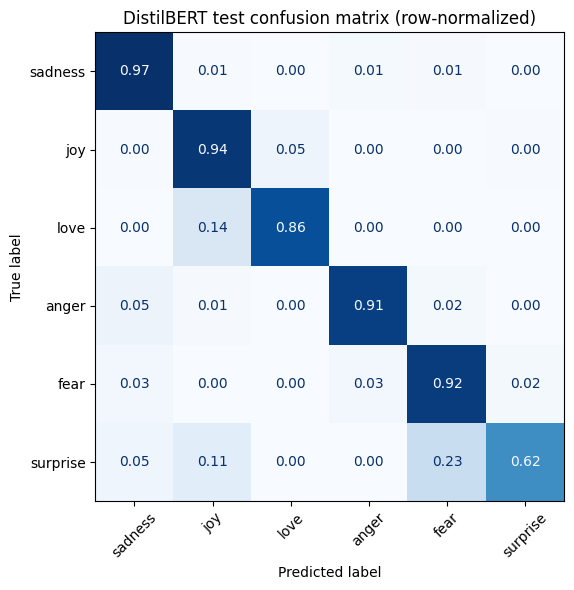

In [35]:
ransformer_classification_report = classification_report(
    transformer_test_labels,
    transformer_test_predictions,
    labels=list(range(len(label_names))),
    target_names=label_names,
    output_dict=True,
    zero_division=0
)

transformer_report_df = pd.DataFrame(
    transformer_classification_report
).transpose()

display(
    transformer_report_df.loc[
        label_names,
        ["precision", "recall", "f1-score", "support"]
    ].round(4)
)

transformer_cm = confusion_matrix(
    transformer_test_labels,
    transformer_test_predictions,
    labels=list(range(len(label_names))),
    normalize="true"
)

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(
    confusion_matrix=transformer_cm,
    display_labels=label_names
).plot(
    ax=ax,
    cmap="Blues",
    colorbar=False,
    values_format=".2f"
)
ax.set_title("DistilBERT test confusion matrix (row-normalized)")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


### 6.3 Transformer evaluation under domain shift

The same 50 manually annotated literary sentences used for the MLP are now
tokenized with DistilBERT's pretrained tokenizer and evaluated without further
training. This tests whether pretraining improves robustness to a different
writing style and vocabulary.


In [36]:
def tokenize_ood_for_transformer(batch):
    return transformer_tokenizer(
        batch["text"],
        truncation=True,
        max_length=TRANSFORMER_MAX_LENGTH
    )


transformer_ood_columns_to_remove = [
    column
    for column in ood_dataset.column_names
    if column != "label"
]

transformer_ood_dataset = ood_dataset.map(
    tokenize_ood_for_transformer,
    batched=True,
    remove_columns=transformer_ood_columns_to_remove
)

transformer_ood_output = transformer_trainer.predict(
    transformer_ood_dataset
)

transformer_ood_logits = transformer_ood_output.predictions
if isinstance(transformer_ood_logits, tuple):
    transformer_ood_logits = transformer_ood_logits[0]

transformer_ood_predictions = np.argmax(
    transformer_ood_logits,
    axis=-1
)

print("DistilBERT out-of-domain results:")
print(
    f"Accuracy: {transformer_ood_output.metrics['test_accuracy']:.4f}"
)
print(
    f"Macro-F1: {transformer_ood_output.metrics['test_macro_f1']:.4f}"
)
print(
    "Correct predictions:",
    int((transformer_ood_predictions == transformer_ood_output.label_ids).sum()),
    "out of",
    len(transformer_ood_output.label_ids)
)


Map:   0%|          | 0/50 [00:00<?, ? examples/s]

DistilBERT out-of-domain results:
Accuracy: 0.5600
Macro-F1: 0.4745
Correct predictions: 28 out of 50


### 6.4 Controlled model comparison

The table reports the two models on identical evaluation sets. Parameter count
and training time provide context for the trade-off between a lightweight model
trained from scratch and a much larger pretrained transformer.


,model,trainable_parameters,training_minutes,test_accuracy,test_macro_f1,ood_accuracy,ood_macro_f1,accuracy_drop_ood,macro_f1_drop_ood
0,Custom MLP,120054,0.7913,0.8715,0.8235,0.40,0.3649,0.4715,0.4585
1,DistilBERT,66958086,3.5670,0.9275,0.8809,0.56,0.4745,0.3675,0.4064


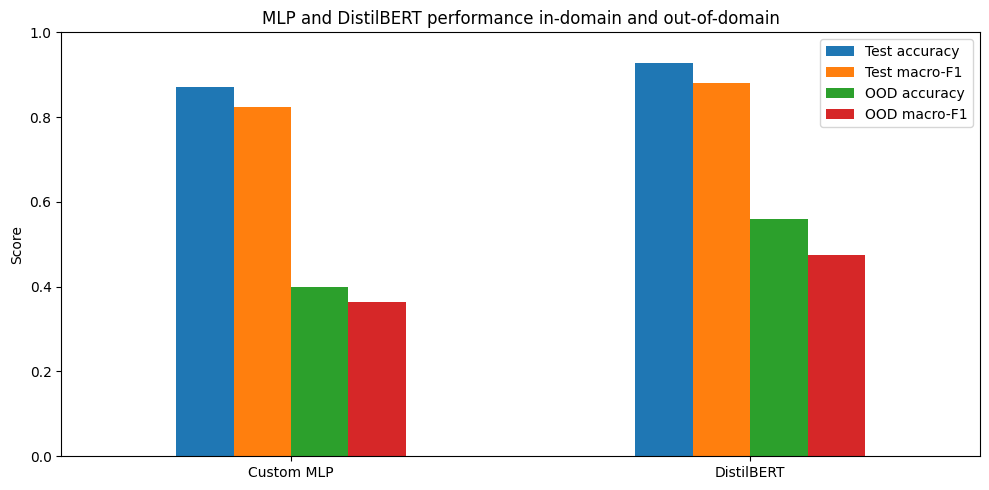

In [37]:
model_comparison_df = pd.DataFrame({
    "model": ["Custom MLP", "DistilBERT"],
    "trainable_parameters": [
        final_parameter_count,
        transformer_parameter_count
    ],
    "training_minutes": [
        final_training_time / 60,
        transformer_training_time / 60
    ],
    "test_accuracy": [
        test_output.metrics["test_accuracy"],
        transformer_test_output.metrics["test_accuracy"]
    ],
    "test_macro_f1": [
        test_output.metrics["test_macro_f1"],
        transformer_test_output.metrics["test_macro_f1"]
    ],
    "ood_accuracy": [
        ood_accuracy,
        transformer_ood_output.metrics["test_accuracy"]
    ],
    "ood_macro_f1": [
        ood_macro_f1,
        transformer_ood_output.metrics["test_macro_f1"]
    ]
})

model_comparison_df["accuracy_drop_ood"] = (
    model_comparison_df["test_accuracy"]
    - model_comparison_df["ood_accuracy"]
)
model_comparison_df["macro_f1_drop_ood"] = (
    model_comparison_df["test_macro_f1"]
    - model_comparison_df["ood_macro_f1"]
)

display(model_comparison_df.round(4))

plot_df = model_comparison_df.set_index("model")[
    [
        "test_accuracy",
        "test_macro_f1",
        "ood_accuracy",
        "ood_macro_f1"
    ]
]

plot_df.plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1),
    rot=0
)
plt.ylabel("Score")
plt.xlabel("")
plt.title("MLP and DistilBERT performance in-domain and out-of-domain")
plt.legend([
    "Test accuracy",
    "Test macro-F1",
    "OOD accuracy",
    "OOD macro-F1"
])
plt.tight_layout()
plt.show()


### 6.5 Interpretation and conclusions

DistilBERT achieved the stronger performance on the official test set. Its
accuracy was 0.9275, compared with 0.8715 for the custom MLP, an improvement of
5.60 percentage points. Its macro-F1 increased from 0.8235 to 0.8809, an
improvement of 5.74 percentage points. The validation macro-F1 improved during
all four fine-tuning epochs and reached 0.9188, so the early-stopping condition
was not triggered.

The transformer improved the F1-score for every emotion class. The largest gain
was for love, whose F1-score increased from 0.7089 to 0.8318. Fear increased
from 0.8397 to 0.9039, while sadness, joy and anger all exceeded 0.92 F1 with
DistilBERT. Surprise remained the most difficult class: its F1-score changed
only slightly, from 0.7087 to 0.7130, and its recall decreased from 0.6818 to
0.6212. This indicates that pretraining reduced many contextual errors but did
not remove the difficulty caused by the small and semantically varied surprise
class.

DistilBERT also generalized better to the manually annotated literary data. Its
out-of-domain accuracy was 0.5600 and macro-F1 was 0.4745, compared with 0.4000
and 0.3649 for the MLP. The accuracy drop between the official and literary
test sets was therefore 0.3675 for DistilBERT and 0.4715 for the MLP. The
transformer's pretrained vocabulary and contextual representations appear to
help with unfamiliar language, although its substantial remaining performance
drop shows that pretraining does not eliminate domain shift.

The improvement comes with a considerable computational cost. DistilBERT has
66,958,086 trainable parameters, approximately 558 times the MLP's 120,054
parameters. In this run it also took about 3.57 minutes to train, compared with
0.79 minutes for the final MLP, making it roughly 4.5 times slower. The MLP
therefore remains an effective lightweight baseline, while DistilBERT provides
the stronger choice when predictive performance and robustness are more
important than model size and training cost.

The out-of-domain results should be interpreted cautiously because the literary
set contains only 50 examples, has an imperfect class balance, and was annotated
by one person. Even with these limitations, the controlled comparison shows two
consistent findings: transfer learning improves both in-domain performance and
robustness, but minority-class ambiguity and domain shift remain important
limitations.
